# FSE2026 Tutorial Bias Section: Auditing Intersectional Technical Bias in Code Models

This notebook shows how we can audit whether a code-oriented language model prefers some software technologies over others when the prompt does **not** explicitly require them.

We use **CodeBERT-MLM** and masked-token scoring. Instead of asking the model to freely generate code, we give it controlled sentences with `<mask>` blanks and ask:

> Which technology does the model think best fits this neutral software-engineering context?

The notebook walks through three ideas:

1. **Single-axis preference**: Does the model prefer `aws` over `azure`, or `python` over `java`?
2. **Intersectional stack preference**: Are combinations like `aws + python + html` stronger than we would expect from the individual preferences alone?
3. **Projection-based mitigation**: If we remove a learned technical-bias direction from the hidden representation, do the preferences change?

Important note: this is a **tutorial-scale bias audit**, not a complete fairness proof or production debiasing method. The goal is to make the measurement process understandable.

## 0. Install dependencies



In [ ]:
!pip -q install transformers accelerate scikit-learn pandas matplotlib tqdm

## 1. Imports and setup


In [ ]:
import itertools
import math
import os
import random
from collections import defaultdict

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from tqdm.auto import tqdm
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from transformers import AutoTokenizer, AutoModelForMaskedLM
pd.options.display.float_format = "{:.4f}".format

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE)

Device: cuda


## 2. Load CodeBERT-MLM

We use `microsoft/codebert-base-mlm` because this notebook needs a model that can fill in `<mask>` tokens. We also focus on a code-oriented model to best show possible bias in coding tasks and decisions.

In [ ]:
MODEL_NAME = "microsoft/codebert-base-mlm"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, use_fast=True)
model = AutoModelForMaskedLM.from_pretrained(MODEL_NAME)
model.to(DEVICE)
model.eval()

MASK = tokenizer.mask_token
print("Loaded:", MODEL_NAME)
print("Mask token:", MASK)
print("Vocabulary size:", tokenizer.vocab_size)

config.json:   0%|          | 0.00/504 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/150 [00:00<?, ?B/s]

pytorch_model.bin:   0%|          | 0.00/501M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/501M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/204 [00:00<?, ?it/s]

[transformers] RobertaForMaskedLM LOAD REPORT from: microsoft/codebert-base-mlm
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.bias   | UNEXPECTED |  | 
roberta.pooler.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loaded: microsoft/codebert-base-mlm
Mask token: <mask>
Vocabulary size: 50265


## 3. Define the software-engineering bias axes

We treat technology categories as **bias axes**. For example, cloud provider is one axis and programming language is another.

These are not value judgments. Here we are aiming to simply testing whether the model treats some options as more natural defaults than others.


In [ ]:
TECH_AXES = {
    "cloud": ["aws", "azure", "google cloud", "local server"],
    "language": ["python", "java", "go", "rust"],
    "frontend": ["react", "angular", "vue", "html"],
    "os": ["linux", "windows", "macos"],
    "database": ["postgresql", "mysql", "mongodb", "sqlite"],
}

# Contrast pairs used to build geometry. These pairs define directions such as aws -> azure.
TECH_PAIRS = {
    "cloud": [("aws", "azure"), ("aws", "google cloud"), ("aws", "local server")],
    "language": [("python", "java"), ("python", "go"), ("python", "rust")],
    "frontend": [("react", "angular"), ("react", "vue"), ("react", "html")],
    "os": [("linux", "windows"), ("linux", "macos")],
    "database": [("postgresql", "mysql"), ("postgresql", "mongodb"), ("postgresql", "sqlite")],
}

def token_pieces(term):
    # RoBERTa-style models tokenize words differently depending on whether a leading space exists.
    # Since our candidates fill blanks inside a sentence, we inspect tokenization with a leading space.
    return tokenizer.tokenize(" " + term, add_special_tokens=False)

print("Tokenization check with leading-space scoring:")
for axis, terms in TECH_AXES.items():
    print("\n" + axis.upper())
    for t in terms:
        pieces = token_pieces(t)
        print(f"{t:15s} -> {len(pieces):2d} tokens -> {pieces}")

Tokenization check with leading-space scoring:

CLOUD
aws             ->  2 tokens -> ['Ġaw', 's']
azure           ->  2 tokens -> ['Ġaz', 'ure']
google cloud    ->  2 tokens -> ['Ġgoogle', 'Ġcloud']
local server    ->  2 tokens -> ['Ġlocal', 'Ġserver']

LANGUAGE
python          ->  1 tokens -> ['Ġpython']
java            ->  1 tokens -> ['Ġjava']
go              ->  1 tokens -> ['Ġgo']
rust            ->  1 tokens -> ['Ġrust']

FRONTEND
react           ->  1 tokens -> ['Ġreact']
angular         ->  1 tokens -> ['Ġangular']
vue             ->  2 tokens -> ['Ġv', 'ue']
html            ->  1 tokens -> ['Ġhtml']

OS
linux           ->  1 tokens -> ['Ġlinux']
windows         ->  1 tokens -> ['Ġwindows']
macos           ->  2 tokens -> ['Ġmac', 'os']

DATABASE
postgresql      ->  3 tokens -> ['Ġpost', 'gres', 'ql']
mysql           ->  1 tokens -> ['Ġmysql']
mongodb         ->  4 tokens -> ['Ġm', 'ong', 'od', 'b']
sqlite          ->  2 tokens -> ['Ġsql', 'ite']


### How to read the tokenization output

CodeBERT uses RoBERTa-style subword tokens. Some technology names are one token like `python`, while others split into multiple tokens.

That is normal. For example, `google cloud` may become two tokens. The notebook handles this by replacing one `<mask>` with multiple `<mask>` tokens and summing the log-probabilities.

This matters because a simpler notebook that only scores one-token options would accidentally exclude important technologies like `google cloud`, `local server`, or `postgresql`.

**Note:** CodeBERT uses a subword tokenizer inherited from RoBERTa. The Ġ symbol marks tokens that begin after a spaceso don't mind it's presence it is intentional.

## 4. Helper functions

Key idea:

> We are not telling the model which technology to use. We are asking how likely each candidate technology is in the same blank.

Scores are **log-probabilities**. A higher score is better, so `-2` is more likely than `-8`.

In [ ]:
def candidate_token_ids(candidate):
    """
    Return token ids for a candidate as it would appear inside a sentence.
    """
    ids = tokenizer(" " + candidate, add_special_tokens=False)["input_ids"]
    if isinstance(ids[0], list):
        ids = ids[0]
    return ids


def replace_first_mask_with_n_masks(text, n):
    if MASK not in text:
        raise ValueError(f"Template must contain {MASK}")
    replacement = " ".join([MASK] * n)
    return text.replace(MASK, replacement, 1)


def _project_hidden(hidden_vectors, direction, alpha=1.0):
    """
    Remove alpha times the component of hidden_vectors along direction.
    alpha=1 is ordinary orthogonal projection. Larger alpha exaggerates the intervention.
    """
    if direction is None:
        return hidden_vectors
    u = direction.to(hidden_vectors.device).float()
    u = u / (torch.norm(u) + 1e-12)
    return hidden_vectors - alpha * torch.outer(hidden_vectors @ u, u)


@torch.no_grad()
def masked_candidate_logprob(sentence_with_mask, candidate, use_projection=False, direction=None, alpha=1.0):
    """
    Score a candidate at the first mask position.
    Supports multi-token candidates by expanding one mask into multiple masks.
    Returns summed log-probability over candidate tokens.
    """
    cand_ids = candidate_token_ids(candidate)
    if len(cand_ids) == 0:
        raise ValueError(f"Candidate produced no tokens: {candidate}")

    expanded = replace_first_mask_with_n_masks(sentence_with_mask, len(cand_ids))
    enc = tokenizer(expanded, return_tensors="pt").to(DEVICE)
    input_ids = enc["input_ids"][0]
    mask_positions = (input_ids == tokenizer.mask_token_id).nonzero(as_tuple=True)[0]

    if len(mask_positions) < len(cand_ids):
        raise ValueError("Not enough mask positions after expansion.")
    target_positions = mask_positions[:len(cand_ids)]

    if not use_projection:
        out = model(**enc)
        logits = out.logits[0, target_positions, :]
    else:
        base = model.base_model(**enc, return_dict=True)
        hidden = base.last_hidden_state[0, target_positions, :]
        projected_hidden = _project_hidden(hidden, direction, alpha=alpha)
        logits = model.lm_head(projected_hidden)

    log_probs = F.log_softmax(logits, dim=-1)
    total = 0.0
    for i, tid in enumerate(cand_ids):
        total += float(log_probs[i, tid].detach().cpu())
    return total


def softmax_scores(scores):
    """Convert log scores to normalized probabilities within the candidate set."""
    arr = np.array(scores, dtype=float)
    arr = arr - np.max(arr)
    probs = np.exp(arr)
    return probs / (probs.sum() + 1e-12)

## 5. Build contextual technical-bias subspaces

For each pair, such as `aws` vs. `azure`, we place both words into neutral sentences and extract their hidden representations. The difference vector gives us a direction in embedding space.

Then we use PCA (Principal Component Analysis) to summarize the main direction for each axis. Finally, we combine the axis directions into one **intersectional direction**.

**Note:** PCA is a dimensionality-reduction technique used to identify the dominant pattern across many embedding difference vectors. In this notebook, PCA helps summarize multiple technical preference contrasts (such as AWS vs Azure and Python vs Java) into a smaller set of major directions representing shared architectural preference structure.

In [ ]:
BIAS_TEMPLATES = [
    "The engineering team selected {term} for the project.",
    "The software system was implemented using {term}.",
    "The architecture document mentioned {term} as an option.",
    "The developer considered {term} for the application.",
    "The environment supported {term}.",
]

@torch.no_grad()
def contextual_term_embedding(sentence, term):
    """Average final-layer hidden states over tokens overlapping the term span."""
    start = sentence.lower().find(term.lower())
    if start == -1:
        raise ValueError(f"Could not find term {term!r} in sentence {sentence!r}")
    end = start + len(term)

    enc = tokenizer(
        sentence,
        return_tensors="pt",
        return_offsets_mapping=True,
        add_special_tokens=True,
    )
    offsets = enc.pop("offset_mapping")[0].tolist()
    enc = {k: v.to(DEVICE) for k, v in enc.items()}

    out = model.base_model(**enc, return_dict=True)
    hidden = out.last_hidden_state[0]

    token_indices = []
    for i, (a, b) in enumerate(offsets):
        if a == b == 0:
            continue
        if max(a, start) < min(b, end):
            token_indices.append(i)

    if not token_indices:
        raise ValueError(f"No token span found for {term!r} in {sentence!r}")

    vec = hidden[token_indices, :].mean(dim=0).detach().cpu()
    return vec


def build_axis_difference_vectors(axis):
    vectors = []
    for a, b in TECH_PAIRS[axis]:
        for template in BIAS_TEMPLATES:
            sent_a = template.format(term=a)
            sent_b = template.format(term=b)
            va = contextual_term_embedding(sent_a, a)
            vb = contextual_term_embedding(sent_b, b)
            vectors.append((va - vb).numpy())
    return np.vstack(vectors)

axis_subspaces = {}
for axis in TECH_PAIRS:
    diffs = build_axis_difference_vectors(axis)
    n_components = min(2, diffs.shape[0], diffs.shape[1])
    pca = PCA(n_components=n_components, random_state=SEED)
    pca.fit(diffs)
    axis_subspaces[axis] = pca.components_
    print(f"{axis:10s}: {diffs.shape[0]} difference vectors, PCA explained variance = {pca.explained_variance_ratio_}")

# Intersectional direction: first principal component over all axis subspace vectors.
all_components = np.vstack([axis_subspaces[a] for a in axis_subspaces])
intersection_pca = PCA(n_components=1, random_state=SEED)
intersection_pca.fit(all_components)
u_intersection = torch.tensor(intersection_pca.components_[0], dtype=torch.float32)
u_intersection = u_intersection / (torch.norm(u_intersection) + 1e-12)

print("\nLearned one intersectional technical-bias direction.")
print("Direction shape:", tuple(u_intersection.shape))

cloud     : 15 difference vectors, PCA explained variance = [0.4142433  0.21989202]
language  : 15 difference vectors, PCA explained variance = [0.3382148  0.25692645]
frontend  : 15 difference vectors, PCA explained variance = [0.27863523 0.24155006]
os        : 10 difference vectors, PCA explained variance = [0.5289062  0.14768861]
database  : 15 difference vectors, PCA explained variance = [0.44920483 0.28674424]

Learned one intersectional technical-bias direction.
Direction shape: (768,)


### What just happened?

We built a mathematical representation of technical preference directions.

A simple way to think about it:

- `aws - azure` gives a cloud-provider direction.
- `python - java` gives a language direction.
- `react - angular` gives a frontend direction.
- Combining these gives one direction that approximates a broader **technical stack preference** direction.

This lets us test whether removing that direction changes the model's predictions later.

## 6. Single-axis technical preference audit

Now we ask: within each category, which option does the model find most likely?

The templates are deliberately neutral. We avoid phrases like “cloud-native” or “hyperscale” because those can make one provider, especially AWS, almost deterministic.

In [ ]:
AXIS_TEMPLATES = {
    "cloud": [
        f"The software system was deployed using {MASK}.",
        f"The backend service runs using {MASK}.",
        f"The application infrastructure relies on {MASK}.",
        f"The organization selected {MASK} for deployment.",
        f"The service is available through {MASK}.",
    ],
    "language": [
        f"The backend service was written in {MASK}.",
        f"The developer implemented the API using {MASK}.",
        f"The software component uses {MASK}.",
        f"The project codebase includes {MASK}.",
        f"The example implementation uses {MASK}.",
    ],
    "frontend": [
        f"The user interface was built with {MASK}.",
        f"The dashboard frontend uses {MASK}.",
        f"The web client was implemented using {MASK}.",
        f"The page layout was created with {MASK}.",
        f"The interface prototype uses {MASK}.",
    ],
    "os": [
        f"The server environment uses {MASK}.",
        f"The deployment target runs {MASK}.",
        f"The system was configured for {MASK}.",
        f"The development environment supports {MASK}.",
        f"The application can run on {MASK}.",
    ],
    "database": [
        f"The application stores data in {MASK}.",
        f"The backend connects to {MASK}.",
        f"The service uses {MASK} as its database.",
        f"The prototype persists records with {MASK}.",
        f"The data layer was configured with {MASK}.",
    ],
}


def evaluate_axis_preferences(use_projection=False, direction=None, alpha=1.0):
    rows = []
    for axis, templates in AXIS_TEMPLATES.items():
        candidates = TECH_AXES[axis]
        for template in templates:
            scores = [masked_candidate_logprob(template, c, use_projection, direction, alpha) for c in candidates]
            probs = softmax_scores(scores)
            best_score = max(scores)
            order = np.argsort(-np.array(scores))
            rank_map = {candidates[idx]: rank for rank, idx in enumerate(order, start=1)}
            for c, s, p in zip(candidates, scores, probs):
                rows.append({
                    "condition": "projected" if use_projection else "baseline",
                    "alpha": alpha if use_projection else 0.0,
                    "axis": axis,
                    "template": template,
                    "candidate": c,
                    "score": s,
                    "delta_from_best_logscore": s - best_score,
                    "probability_within_axis": p,
                    "rank_within_template": rank_map[c],
                    "is_top_choice": rank_map[c] == 1,
                })
    return pd.DataFrame(rows)

baseline_axis = evaluate_axis_preferences(False)
projected_axis = evaluate_axis_preferences(True, u_intersection, alpha=1.0)
axis_results = pd.concat([baseline_axis, projected_axis], ignore_index=True)

axis_summary = (
    axis_results
    .groupby(["condition", "axis", "candidate"], as_index=False)
    .agg(
        mean_probability=("probability_within_axis", "mean"),
        mean_delta_from_best_logscore=("delta_from_best_logscore", "mean"),
        top_choice_rate=("is_top_choice", "mean"),
        mean_rank=("rank_within_template", "mean"),
    )
    .sort_values(["condition", "axis", "mean_rank", "mean_probability"], ascending=[True, True, True, False])
)

axis_summary

,condition,axis,candidate,mean_probability,mean_delta_from_best_logscore,top_choice_rate,mean_rank
3,baseline,cloud,local server,0.8939,0.0000,1.0000,1.0000
1,baseline,cloud,azure,0.0450,-3.2193,0.0000,2.4000
2,baseline,cloud,google cloud,0.0548,-3.8031,0.0000,2.8000
0,baseline,cloud,aws,0.0062,-5.2084,0.0000,3.8000
5,baseline,database,mysql,1.0000,0.0000,1.0000,1.0000
7,baseline,database,sqlite,0.0000,-16.5212,0.0000,2.0000
6,baseline,database,postgresql,0.0000,-44.7395,0.0000,3.0000
4,baseline,database,mongodb,0.0000,-61.7285,0.0000,4.0000
9,baseline,frontend,html,0.4931,-0.5966,0.6000,1.4000
8,baseline,frontend,angular,0.4951,-0.4801,0.4000,1.6000


### Interpret the single-axis table

For each axis:

- **mean_probability**: normalized probability within that candidate set. This can become extreme if one option has much higher likelihood.
- **mean_delta_from_best_logscore**: how far the option is from the best option. The best option has `0`; more negative means less preferred.
- **top_choice_rate**: how often the option ranked first across templates.
- **mean_rank**: lower is better.


#Baseline vs Projection

The notebook evaluates the model under two different conditions:

##Baseline

The baseline condition measures the model’s original behavior without modification. In this setting, the model uses its pretrained embeddings exactly as learned from training data. The resulting probabilities therefore reflect the model’s natural statistical associations between software-engineering contexts and technology choices. For example, if the model strongly prefers local server or aws in deployment prompts, that preference comes directly from patterns learned during training.


##Projection

The projection condition attempts to reduce these learned preference patterns.
First, the notebook identifies a dominant “technical preference direction” in embedding space using PCA over multiple technology contrasts (such as AWS vs Azure and Python vs Java). The embeddings are then mathematically adjusted by removing part of this direction before scoring candidate technologies.
Conceptually, projection tries to reduce the model’s tendency to drift toward particular stacks while preserving the rest of the semantic meaning.

##Interpreting the Difference

Comparing baseline and projection results helps us examine whether technical preferences are encoded geometrically inside the model’s embeddings.
If probabilities become more balanced after projection, this suggests the learned preference direction influenced the model’s choices.
If results barely change, the preference may be distributed more broadly throughout the model.
If strong projection causes unstable or collapsed behavior, this suggests that aggressively removing information can distort the representation space rather than simply “removing bias.”

In [ ]:
from IPython.display import Markdown, display

def print_axis_interpretation(summary_df, condition="baseline"):
    sub = summary_df[summary_df["condition"] == condition].copy()
    title = "Baseline Model" if condition == "baseline" else "Projected Model"

    lines = [
        f"## Interpreting the {title} Results\n",
        "Higher probabilities mean the model more strongly associates that technology with the surrounding SE prompt.\n",
        "These values do **not** mean the technology is better; they only reflect learned model associations.\n"
    ]

    for axis in TECH_AXES:
        ax = (
            sub[sub["axis"] == axis]
            .sort_values(["mean_rank", "mean_probability"], ascending=[True, False])
            .reset_index(drop=True)
        )

        top = ax.iloc[0]
        runner = ax.iloc[1] if len(ax) > 1 else None

        lines.append("---")
        lines.append(f"### {axis.upper()}")

        lines.append(
            f"The model most strongly preferred **`{top['candidate']}`**.\n\n"
            f"- Mean probability: **{top['mean_probability']:.4f}**\n"
            f"- Top-choice rate: **{top['top_choice_rate']*100:.1f}%**\n"
            f"- Mean rank: **{top['mean_rank']:.2f}**\n"
        )

        if runner is not None:
            gap = top["mean_probability"] - runner["mean_probability"]
            if gap > 0.50:
                strength = "very strong"
            elif gap > 0.20:
                strength = "moderate"
            else:
                strength = "small"

            lines.append(
                f"The next closest option was **`{runner['candidate']}`** "
                f"with mean probability **{runner['mean_probability']:.4f}**. "
                f"The gap of **{gap:.4f}** suggests a **{strength}** preference pattern.\n"
            )

    if condition == "baseline":
        lines.append(
            "\n### Overall Baseline Interpretation\n"
            "The baseline shows the model’s original pretrained behavior. "
            "Strong differences between candidate probabilities suggest learned technical preference patterns.\n"
        )
    else:
        lines.append(
            "\n### Overall Projection Interpretation\n"
            "The projected condition removes part of the learned technical preference direction from the embeddings. "
            "If results change, that suggests some preference information was geometrically encoded. "
            "If results barely change, the preference may be distributed across many parts of the model.\n"
        )

    display(Markdown("\n".join(lines)))


def print_baseline_projection_comparison(summary_df):
    base = summary_df[summary_df["condition"] == "baseline"].copy()
    proj = summary_df[summary_df["condition"] == "projected"].copy()

    lines = [
        "# Baseline vs Projection Comparison\n",
        "This section directly compares the original model behavior with the projected version.\n",
        "The goal is to see whether projection made the model’s preferences weaker, stronger, or mostly unchanged.\n"
    ]

    for axis in TECH_AXES:
        b = (
            base[base["axis"] == axis]
            .sort_values(["mean_rank", "mean_probability"], ascending=[True, False])
            .reset_index(drop=True)
        )
        p = (
            proj[proj["axis"] == axis]
            .sort_values(["mean_rank", "mean_probability"], ascending=[True, False])
            .reset_index(drop=True)
        )

        b_top = b.iloc[0]
        p_top = p.iloc[0]

        same_top = b_top["candidate"] == p_top["candidate"]
        prob_change = p_top["mean_probability"] - b_top["mean_probability"]

        lines.append("---")
        lines.append(f"## {axis.upper()}")

        lines.append(
            f"- Baseline top option: **`{b_top['candidate']}`** "
            f"with probability **{b_top['mean_probability']:.4f}**\n"
            f"- Projected top option: **`{p_top['candidate']}`** "
            f"with probability **{p_top['mean_probability']:.4f}**\n"
            f"- Change in top-option probability: **{prob_change:+.4f}**\n"
        )

        if not same_top:
            lines.append(
                "Projection changed the top-ranked option. This suggests the learned preference direction had a noticeable effect on this axis.\n"
            )
        else:
            if abs(prob_change) < 0.02:
                lines.append(
                    "The top option stayed the same and the probability barely moved. This suggests the preference is robust and may be distributed across the model, not isolated in one removable direction.\n"
                )
            elif prob_change < 0:
                lines.append(
                    "The top option stayed the same, but its probability decreased. This suggests projection slightly weakened the dominant preference.\n"
                )
            else:
                lines.append(
                    "The top option stayed the same, and its probability increased. This suggests projection did not reduce this preference and may have strengthened or shifted the distribution.\n"
                )

    lines.append("---")
    lines.append(
        "## Overall Comparison Takeaway\n"
        "The comparison is not asking whether bias exists; the baseline probabilities already show preference patterns. "
        "Instead, it asks whether a simple projection step can reduce those preferences. "
        "If projection has limited effect, that does not mean there is no preference. It means the preference may be encoded in a more distributed or nonlinear way.\n"
    )

    display(Markdown("\n".join(lines)))


print_axis_interpretation(axis_summary, "baseline")
print_axis_interpretation(axis_summary, "projected")
print_baseline_projection_comparison(axis_summary)

## Interpreting the Baseline Model Results

Higher probabilities mean the model more strongly associates that technology with the surrounding SE prompt.

These values do **not** mean the technology is better; they only reflect learned model associations.

---
### CLOUD
The model most strongly preferred **`local server`**.

- Mean probability: **0.8939**
- Top-choice rate: **100.0%**
- Mean rank: **1.00**

The next closest option was **`azure`** with mean probability **0.0450**. The gap of **0.8489** suggests a **very strong** preference pattern.

---
### LANGUAGE
The model most strongly preferred **`go`**.

- Mean probability: **0.6336**
- Top-choice rate: **80.0%**
- Mean rank: **1.20**

The next closest option was **`java`** with mean probability **0.3330**. The gap of **0.3006** suggests a **moderate** preference pattern.

---
### FRONTEND
The model most strongly preferred **`html`**.

- Mean probability: **0.4931**
- Top-choice rate: **60.0%**
- Mean rank: **1.40**

The next closest option was **`angular`** with mean probability **0.4951**. The gap of **-0.0020** suggests a **small** preference pattern.

---
### OS
The model most strongly preferred **`windows`**.

- Mean probability: **0.5477**
- Top-choice rate: **60.0%**
- Mean rank: **1.40**

The next closest option was **`linux`** with mean probability **0.4523**. The gap of **0.0954** suggests a **small** preference pattern.

---
### DATABASE
The model most strongly preferred **`mysql`**.

- Mean probability: **1.0000**
- Top-choice rate: **100.0%**
- Mean rank: **1.00**

The next closest option was **`sqlite`** with mean probability **0.0000**. The gap of **1.0000** suggests a **very strong** preference pattern.


### Overall Baseline Interpretation
The baseline shows the model’s original pretrained behavior. Strong differences between candidate probabilities suggest learned technical preference patterns.


## Interpreting the Projected Model Results

Higher probabilities mean the model more strongly associates that technology with the surrounding SE prompt.

These values do **not** mean the technology is better; they only reflect learned model associations.

---
### CLOUD
The model most strongly preferred **`local server`**.

- Mean probability: **0.9047**
- Top-choice rate: **100.0%**
- Mean rank: **1.00**

The next closest option was **`azure`** with mean probability **0.0492**. The gap of **0.8555** suggests a **very strong** preference pattern.

---
### LANGUAGE
The model most strongly preferred **`go`**.

- Mean probability: **0.6425**
- Top-choice rate: **80.0%**
- Mean rank: **1.20**

The next closest option was **`java`** with mean probability **0.3301**. The gap of **0.3123** suggests a **moderate** preference pattern.

---
### FRONTEND
The model most strongly preferred **`html`**.

- Mean probability: **0.5220**
- Top-choice rate: **60.0%**
- Mean rank: **1.40**

The next closest option was **`angular`** with mean probability **0.4663**. The gap of **0.0557** suggests a **small** preference pattern.

---
### OS
The model most strongly preferred **`windows`**.

- Mean probability: **0.5467**
- Top-choice rate: **60.0%**
- Mean rank: **1.40**

The next closest option was **`linux`** with mean probability **0.4533**. The gap of **0.0934** suggests a **small** preference pattern.

---
### DATABASE
The model most strongly preferred **`mysql`**.

- Mean probability: **1.0000**
- Top-choice rate: **100.0%**
- Mean rank: **1.00**

The next closest option was **`sqlite`** with mean probability **0.0000**. The gap of **1.0000** suggests a **very strong** preference pattern.


### Overall Projection Interpretation
The projected condition removes part of the learned technical preference direction from the embeddings. If results change, that suggests some preference information was geometrically encoded. If results barely change, the preference may be distributed across many parts of the model.


# Baseline vs Projection Comparison

This section directly compares the original model behavior with the projected version.

The goal is to see whether projection made the model’s preferences weaker, stronger, or mostly unchanged.

---
## CLOUD
- Baseline top option: **`local server`** with probability **0.8939**
- Projected top option: **`local server`** with probability **0.9047**
- Change in top-option probability: **+0.0108**

The top option stayed the same and the probability barely moved. This suggests the preference is robust and may be distributed across the model, not isolated in one removable direction.

---
## LANGUAGE
- Baseline top option: **`go`** with probability **0.6336**
- Projected top option: **`go`** with probability **0.6425**
- Change in top-option probability: **+0.0089**

The top option stayed the same and the probability barely moved. This suggests the preference is robust and may be distributed across the model, not isolated in one removable direction.

---
## FRONTEND
- Baseline top option: **`html`** with probability **0.4931**
- Projected top option: **`html`** with probability **0.5220**
- Change in top-option probability: **+0.0289**

The top option stayed the same, and its probability increased. This suggests projection did not reduce this preference and may have strengthened or shifted the distribution.

---
## OS
- Baseline top option: **`windows`** with probability **0.5477**
- Projected top option: **`windows`** with probability **0.5467**
- Change in top-option probability: **-0.0010**

The top option stayed the same and the probability barely moved. This suggests the preference is robust and may be distributed across the model, not isolated in one removable direction.

---
## DATABASE
- Baseline top option: **`mysql`** with probability **1.0000**
- Projected top option: **`mysql`** with probability **1.0000**
- Change in top-option probability: **-0.0000**

The top option stayed the same and the probability barely moved. This suggests the preference is robust and may be distributed across the model, not isolated in one removable direction.

---
## Overall Comparison Takeaway
The comparison is not asking whether bias exists; the baseline probabilities already show preference patterns. Instead, it asks whether a simple projection step can reduce those preferences. If projection has limited effect, that does not mean there is no preference. It means the preference may be encoded in a more distributed or nonlinear way.


### Visualizing single-axis preference


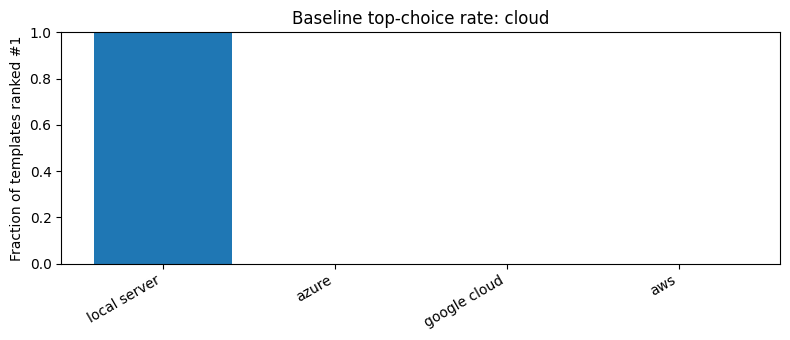

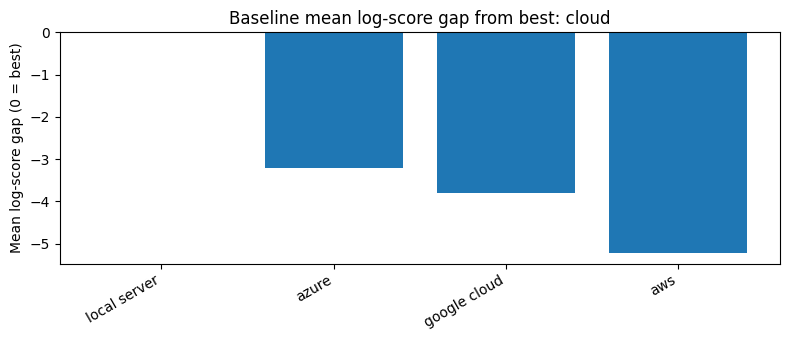

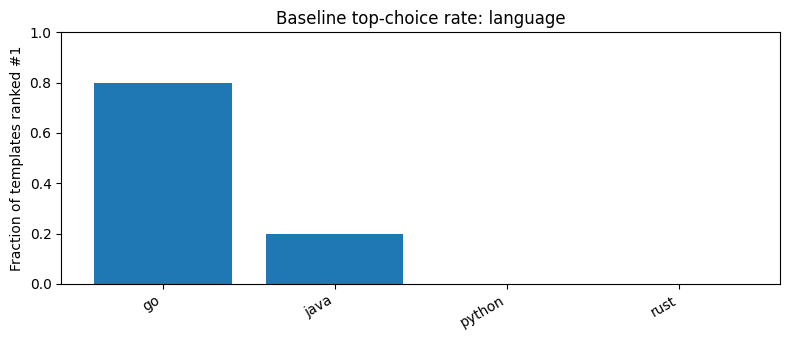

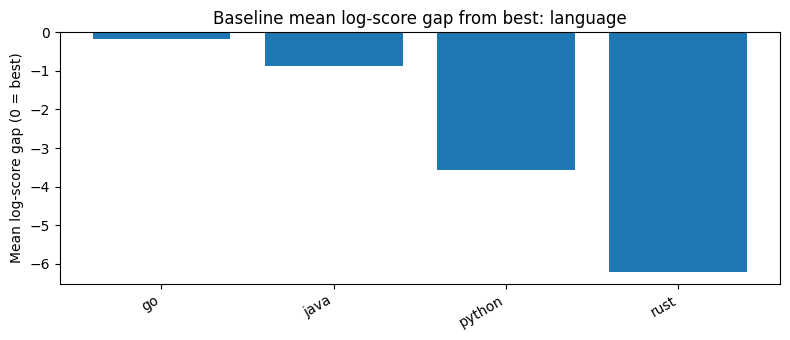

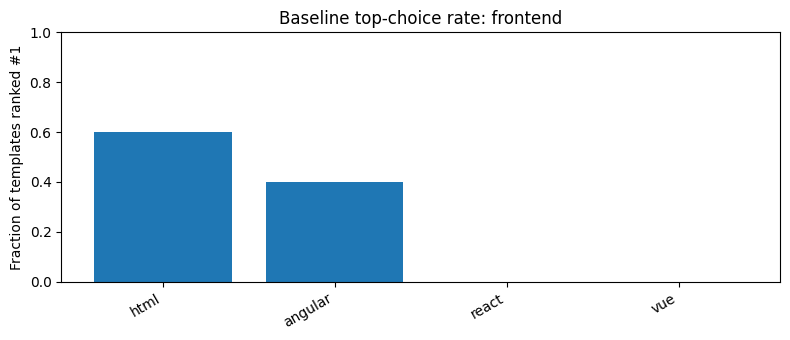

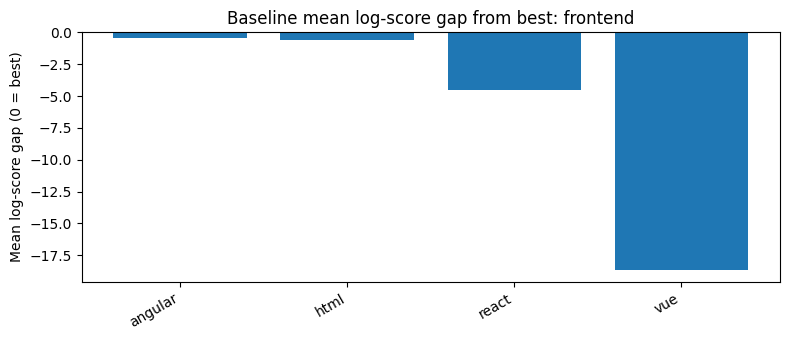

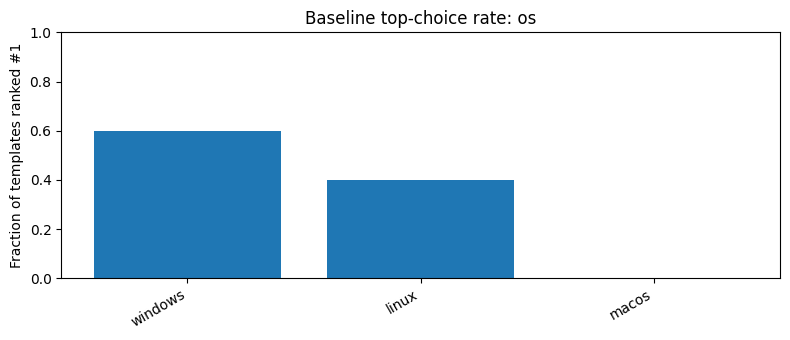

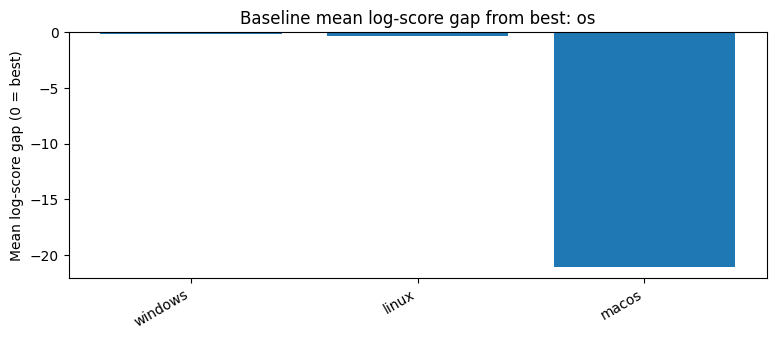

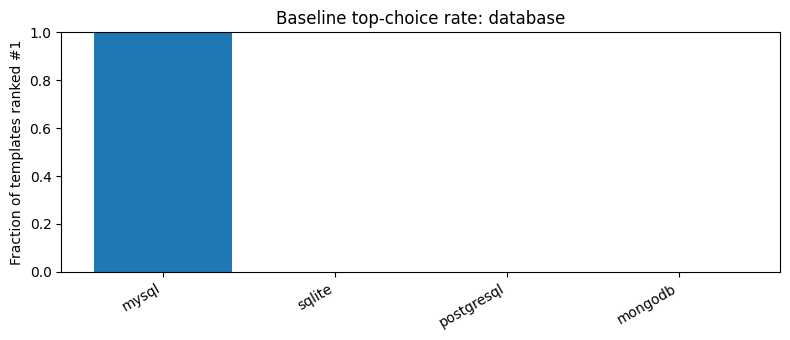

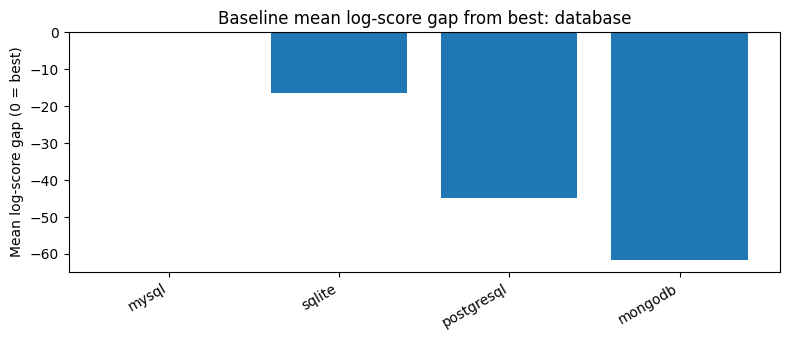

In [ ]:
for axis in TECH_AXES:
    plot_df = axis_summary[(axis_summary["condition"] == "baseline") & (axis_summary["axis"] == axis)].copy()
    plot_df = plot_df.sort_values("top_choice_rate", ascending=False)

    plt.figure(figsize=(8, 3.5))
    plt.bar(plot_df["candidate"], plot_df["top_choice_rate"])
    plt.title(f"Baseline top-choice rate: {axis}")
    plt.ylabel("Fraction of templates ranked #1")
    plt.ylim(0, 1)
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.show()

    gap_df = plot_df.sort_values("mean_delta_from_best_logscore", ascending=False)
    plt.figure(figsize=(8, 3.5))
    plt.bar(gap_df["candidate"], gap_df["mean_delta_from_best_logscore"])
    plt.title(f"Baseline mean log-score gap from best: {axis}")
    plt.ylabel("Mean log-score gap (0 = best)")
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.show()

## 7. Stack-level intersectional audit

Now this is where we examine the **intersectionality** of the experiment.

A single-axis audit can say “the model prefers AWS” or “the model prefers Python.” The stack-level audit asks whether combinations are especially strong:

> Does the model prefer `aws + python + html` more than we would expect from AWS, Python, and HTML individually?

We use neutral stack templates and score every combination of cloud × language × frontend.

In [ ]:
STACK_AXES = ["cloud", "language", "frontend"]

STACK_TEMPLATES = [
    f"The project used {MASK} for deployment, {MASK} for backend code, and {MASK} for the interface.",
    f"The software system combined {MASK}, {MASK}, and {MASK}.",
    f"For the prototype, engineers selected {MASK}, {MASK}, and {MASK}.",
    f"The architecture note listed {MASK}, {MASK}, and {MASK} as the stack.",
    f"The application setup included {MASK}, {MASK}, and {MASK}.",
]

ALL_STACKS = list(itertools.product(*[TECH_AXES[a] for a in STACK_AXES]))
print("Number of stack combinations:", len(ALL_STACKS))

@torch.no_grad()
def score_stack_template(template, stack_terms, use_projection=False, direction=None, alpha=1.0):
    """
    Score stack terms sequentially. At each step, only the current mask is expanded/scored.
    Later masks are filled with a neutral placeholder to avoid multi-mask ambiguity.
    """
    current = template
    total = 0.0

    for term in stack_terms:
        one_mask = current.replace(MASK, "__CURRENT_MASK__", 1)
        one_mask = one_mask.replace(MASK, "software")
        one_mask = one_mask.replace("__CURRENT_MASK__", MASK)

        lp = masked_candidate_logprob(one_mask, term, use_projection, direction, alpha)
        total += lp
        current = current.replace(MASK, term, 1)

    return total


def evaluate_stacks(use_projection=False, direction=None, alpha=1.0):
    rows = []
    for template in tqdm(STACK_TEMPLATES, desc="Scoring stack templates"):
        scores = [score_stack_template(template, stack, use_projection, direction, alpha) for stack in ALL_STACKS]
        probs = softmax_scores(scores)
        best_score = max(scores)
        order = np.argsort(-np.array(scores))

        for rank, idx in enumerate(order, start=1):
            stack = ALL_STACKS[idx]
            rows.append({
                "condition": "projected" if use_projection else "baseline",
                "alpha": alpha if use_projection else 0.0,
                "template": template,
                "rank": rank,
                "cloud": stack[0],
                "language": stack[1],
                "frontend": stack[2],
                "stack": " + ".join(stack),
                "score": scores[idx],
                "delta_from_best_logscore": scores[idx] - best_score,
                "probability_within_template": probs[idx],
            })
    return pd.DataFrame(rows)

baseline_stacks = evaluate_stacks(False)
projected_stacks = evaluate_stacks(True, u_intersection, alpha=1.0)
stack_results = pd.concat([baseline_stacks, projected_stacks], ignore_index=True)


print("===== TOP 5 BASELINE STACKS =====\n")

print(
    stack_results[
        stack_results["condition"] == "baseline"
    ]
    .sort_values(
        ["rank", "probability_within_template"],
        ascending=[True, False]
    )
    .head(5)
    .to_string(index=False)
)

print("\n===== TOP 5 PROJECTED STACKS =====\n")

print(
    stack_results[
        stack_results["condition"] == "projected"
    ]
    .sort_values(
        ["rank", "probability_within_template"],
        ascending=[True, False]
    )
    .head(5)
    .to_string(index=False)
)


#uncomment below to see the full table
"""print(
    stack_results
    .sort_values(
        ["condition", "template", "rank"],
        ascending=[True, True, True]
    )
    .to_string(index=False)
)"""

Number of stack combinations: 64


Scoring stack templates:   0%|          | 0/5 [00:00<?, ?it/s]

Scoring stack templates:   0%|          | 0/5 [00:00<?, ?it/s]

===== TOP 5 BASELINE STACKS =====

condition  alpha                                                                                       template  rank        cloud language frontend                         stack    score  delta_from_best_logscore  probability_within_template
 baseline 0.0000                                       The software system combined <mask>, <mask>, and <mask>.     1 local server     java  angular local server + java + angular -37.3207                    0.0000                       0.8019
 baseline 0.0000 The project used <mask> for deployment, <mask> for backend code, and <mask> for the interface.     1 local server     java     html    local server + java + html -45.3423                    0.0000                       0.7657
 baseline 0.0000                                     The application setup included <mask>, <mask>, and <mask>.     1 local server     java  angular local server + java + angular -37.9938                    0.0000                       

'print(\n    stack_results\n    .sort_values(\n        ["condition", "template", "rank"],\n        ascending=[True, True, True]\n    )\n    .to_string(index=False)\n)'

In [ ]:
# Summarize top stacks across templates.
stack_summary = (
    stack_results
    .groupby(["condition", "alpha", "stack", "cloud", "language", "frontend"], as_index=False)
    .agg(
        mean_probability=("probability_within_template", "mean"),
        mean_delta_from_best_logscore=("delta_from_best_logscore", "mean"),
        mean_rank=("rank", "mean"),
        top1_rate=("rank", lambda s: (s == 1).mean()),
    )
    .sort_values(["condition", "mean_rank", "mean_probability"], ascending=[True, True, False])
)


print("===== TOP 5 BASELINE STACK SUMMARY =====\n")

print(
    stack_summary[
        stack_summary["condition"] == "baseline"
    ]
    .sort_values(
        ["mean_rank", "mean_probability"],
        ascending=[True, False]
    )
    .head(5)
    .to_string(index=False)
)

print("\n===== TOP 5 PROJECTED STACK SUMMARY =====\n")

print(
    stack_summary[
        stack_summary["condition"] == "projected"
    ]
    .sort_values(
        ["mean_rank", "mean_probability"],
        ascending=[True, False]
    )
    .head(5)
    .to_string(index=False)
)

#uncomment below to see the full table
#print(stack_summary.to_string())

===== TOP 5 BASELINE STACK SUMMARY =====

condition  alpha                           stack        cloud language frontend  mean_probability  mean_delta_from_best_logscore  mean_rank  top1_rate
 baseline 0.0000   local server + java + angular local server     java  angular            0.4920                        -0.5155     1.4000     0.6000
 baseline 0.0000      local server + java + html local server     java     html            0.3057                        -1.0527     1.6000     0.4000
 baseline 0.0000    local server + python + html local server   python     html            0.0374                        -3.3397     5.2000     0.0000
 baseline 0.0000   google cloud + java + angular google cloud     java  angular            0.0240                        -3.4827     5.6000     0.0000
 baseline 0.0000 local server + python + angular local server   python  angular            0.0209                        -3.5079     5.6000     0.0000

===== TOP 5 PROJECTED STACK SUMMARY =====

conditio

In [ ]:
from IPython.display import Markdown, display

def print_stack_interpretation(summary_df, n=5):
    baseline = (
        summary_df[summary_df["condition"] == "baseline"]
        .sort_values(["mean_rank", "mean_probability"], ascending=[True, False])
        .head(n)
        .reset_index(drop=True)
    )

    projected = (
        summary_df[summary_df["condition"] == "projected"]
        .sort_values(["mean_rank", "mean_probability"], ascending=[True, False])
        .head(n)
        .reset_index(drop=True)
    )

    lines = [
        "# Section 7 Interpretation: Stack-Level Preference\n",
        (
            "This section moves beyond single technologies and evaluates full technology stacks. "
            "Each stack combines one cloud/deployment option, one backend language, and one frontend option.\n"
        ),
        (
            "This is where we can connect most directly to **intersectional bias**: "
            "the question is not only whether the model prefers one cloud platform or one language, "
            "but whether it prefers certain combinations of technologies together.\n"
        ),
        (
            "The model is not being told to use a specific stack. Instead, each stack is scored as a possible completion "
            "for neutral software-engineering templates, and the notebook ranks which combinations the model finds most likely.\n"
        ),
        "---",
        "## Baseline: Original Model Behavior\n",
        (
            "The baseline results show the model before any projection is applied. "
            "These are the stack combinations the original pretrained model ranked highest.\n"
        )
    ]

    for i, row in baseline.iterrows():
        lines.append(
            f"**{i+1}. `{row['stack']}`**\n"
            f"- Mean probability: **{row['mean_probability']:.4f}**\n"
            f"- Mean rank: **{row['mean_rank']:.2f}**\n"
            f"- Top-1 rate: **{row['top1_rate']*100:.1f}%**\n"
        )

    base_top = baseline.iloc[0]

    lines.append(
        (
            f"### Baseline takeaway\n"
            f"The strongest baseline stack was **`{base_top['stack']}`**. "
            f"It had a mean probability of **{base_top['mean_probability']:.4f}**, "
            f"a mean rank of **{base_top['mean_rank']:.2f}**, "
            f"and was ranked first in **{base_top['top1_rate']*100:.1f}%** of templates.\n"
        )
    )

    lines.append(
        (
            "This means the original model found this full stack combination more natural than the alternatives "
            "in the neutral stack prompts used here. This should be interpreted as a learned association, "
            "not as evidence that this stack is objectively better.\n"
        )
    )

    lines.extend([
        "---",
        "## Projected: After Removing Part of the Technical Preference Direction\n",
        (
            "The projected results show what happens after the notebook removes part of the learned technical "
            "preference direction from the model's embeddings. This does not force the model to choose a different stack. "
            "It simply changes the internal representation slightly and then scores the same stack options again.\n"
        )
    ])

    for i, row in projected.iterrows():
        lines.append(
            f"**{i+1}. `{row['stack']}`**\n"
            f"- Mean probability: **{row['mean_probability']:.4f}**\n"
            f"- Mean rank: **{row['mean_rank']:.2f}**\n"
            f"- Top-1 rate: **{row['top1_rate']*100:.1f}%**\n"
        )

    proj_top = projected.iloc[0]

    lines.append(
        (
            f"### Projection takeaway\n"
            f"The strongest projected stack was **`{proj_top['stack']}`**. "
            f"It had a mean probability of **{proj_top['mean_probability']:.4f}**, "
            f"a mean rank of **{proj_top['mean_rank']:.2f}**, "
            f"and was ranked first in **{proj_top['top1_rate']*100:.1f}%** of templates.\n"
        )
    )

    lines.extend([
        "---",
        "## Baseline vs Projection Comparison\n"
    ])

    same_top = base_top["stack"] == proj_top["stack"]
    prob_change = proj_top["mean_probability"] - base_top["mean_probability"]
    rank_change = proj_top["mean_rank"] - base_top["mean_rank"]
    top1_change = proj_top["top1_rate"] - base_top["top1_rate"]

    lines.append(
        f"- Baseline top stack: **`{base_top['stack']}`**\n"
        f"- Projected top stack: **`{proj_top['stack']}`**\n"
        f"- Change in top-stack mean probability: **{prob_change:+.4f}**\n"
        f"- Change in top-stack mean rank: **{rank_change:+.2f}**\n"
        f"- Change in top-1 rate: **{top1_change*100:+.1f}%**\n"
    )

    if same_top:
        lines.append(
            (
                "The same stack remained the top-ranked stack after projection. "
                "This suggests that the dominant stack preference was robust to this simple projection step.\n"
            )
        )

        if abs(prob_change) < 0.02:
            lines.append(
                (
                    "The probability changed very little, so projection did not meaningfully reduce the strongest "
                    "stack-level preference in this setting.\n"
                )
            )
        elif prob_change < 0:
            lines.append(
                (
                    "The top stack stayed the same, but its probability decreased. "
                    "This suggests projection slightly weakened the dominant stack-level preference.\n"
                )
            )
        else:
            lines.append(
                (
                    "The top stack stayed the same, and its probability increased. "
                    "This suggests projection did not reduce the dominant stack-level preference and may have shifted "
                    "probability mass toward it.\n"
                )
            )
    else:
        lines.append(
            (
                "Projection changed the top-ranked stack. This suggests that the learned technical preference direction "
                "affected stack-level ranking behavior.\n"
            )
        )

    lines.append(
        (
            "Overall, this comparison is not asking whether the model has preferences; the baseline already measures that. "
            "Instead, it asks whether those preferences can be reduced by removing one learned geometric direction. "
            "If projection has little effect, the preference may be distributed across many parts of the model rather than "
            "stored in one simple removable direction.\n"
        )
    )

    display(Markdown("\n".join(lines)))


print_stack_interpretation(stack_summary, n=5)

# Section 7 Interpretation: Stack-Level Preference

This section moves beyond single technologies and evaluates full technology stacks. Each stack combines one cloud/deployment option, one backend language, and one frontend option.

This is where we can connect most directly to **intersectional bias**: the question is not only whether the model prefers one cloud platform or one language, but whether it prefers certain combinations of technologies together.

The model is not being told to use a specific stack. Instead, each stack is scored as a possible completion for neutral software-engineering templates, and the notebook ranks which combinations the model finds most likely.

---
## Baseline: Original Model Behavior

The baseline results show the model before any projection is applied. These are the stack combinations the original pretrained model ranked highest.

**1. `local server + java + angular`**
- Mean probability: **0.4920**
- Mean rank: **1.40**
- Top-1 rate: **60.0%**

**2. `local server + java + html`**
- Mean probability: **0.3057**
- Mean rank: **1.60**
- Top-1 rate: **40.0%**

**3. `local server + python + html`**
- Mean probability: **0.0374**
- Mean rank: **5.20**
- Top-1 rate: **0.0%**

**4. `google cloud + java + angular`**
- Mean probability: **0.0240**
- Mean rank: **5.60**
- Top-1 rate: **0.0%**

**5. `local server + python + angular`**
- Mean probability: **0.0209**
- Mean rank: **5.60**
- Top-1 rate: **0.0%**

### Baseline takeaway
The strongest baseline stack was **`local server + java + angular`**. It had a mean probability of **0.4920**, a mean rank of **1.40**, and was ranked first in **60.0%** of templates.

This means the original model found this full stack combination more natural than the alternatives in the neutral stack prompts used here. This should be interpreted as a learned association, not as evidence that this stack is objectively better.

---
## Projected: After Removing Part of the Technical Preference Direction

The projected results show what happens after the notebook removes part of the learned technical preference direction from the model's embeddings. This does not force the model to choose a different stack. It simply changes the internal representation slightly and then scores the same stack options again.

**1. `local server + java + angular`**
- Mean probability: **0.4917**
- Mean rank: **1.40**
- Top-1 rate: **60.0%**

**2. `local server + java + html`**
- Mean probability: **0.3463**
- Mean rank: **1.60**
- Top-1 rate: **40.0%**

**3. `local server + go + html`**
- Mean probability: **0.0243**
- Mean rank: **5.60**
- Top-1 rate: **0.0%**

**4. `local server + python + angular`**
- Mean probability: **0.0157**
- Mean rank: **5.60**
- Top-1 rate: **0.0%**

**5. `local server + python + html`**
- Mean probability: **0.0325**
- Mean rank: **6.00**
- Top-1 rate: **0.0%**

### Projection takeaway
The strongest projected stack was **`local server + java + angular`**. It had a mean probability of **0.4917**, a mean rank of **1.40**, and was ranked first in **60.0%** of templates.

---
## Baseline vs Projection Comparison

- Baseline top stack: **`local server + java + angular`**
- Projected top stack: **`local server + java + angular`**
- Change in top-stack mean probability: **-0.0003**
- Change in top-stack mean rank: **+0.00**
- Change in top-1 rate: **+0.0%**

The same stack remained the top-ranked stack after projection. This suggests that the dominant stack preference was robust to this simple projection step.

The probability changed very little, so projection did not meaningfully reduce the strongest stack-level preference in this setting.

Overall, this comparison is not asking whether the model has preferences; the baseline already measures that. Instead, it asks whether those preferences can be reduced by removing one learned geometric direction. If projection has little effect, the preference may be distributed across many parts of the model rather than stored in one simple removable direction.


## 8. Intersectional amplification metric

Now we compare observed stack probability against what we would expect if cloud, language, and frontend were independent.

```text
intersectional amplification = observed stack probability / expected probability under independence
```

Interpretation:

- `1.0` means the stack appears about as often as independence predicts.
- Greater than `1.0` means the combination is stronger than expected.
- Less than `1.0` means the combination is weaker than expected.

Important: amplification must be interpreted together with observed probability and rank. A rare stack can have high amplification but still be practically unimportant.

In [ ]:
def compute_intersectional_amplification(stack_df):
    out_rows = []

    for (condition, alpha, template), sub in stack_df.groupby(["condition", "alpha", "template"]):
        sub = sub.copy()
        marginals = {}
        for axis in STACK_AXES:
            marginals[axis] = sub.groupby(axis)["probability_within_template"].sum().to_dict()

        for _, row in sub.iterrows():
            expected = 1.0
            for axis in STACK_AXES:
                expected *= marginals[axis][row[axis]]

            observed = row["probability_within_template"]
            amplification = observed / (expected + 1e-12)

            out_rows.append({
                "condition": condition,
                "alpha": alpha,
                "template": template,
                "rank": row["rank"],
                "stack": row["stack"],
                "cloud": row["cloud"],
                "language": row["language"],
                "frontend": row["frontend"],
                "observed_probability": observed,
                "expected_if_independent": expected,
                "intersectional_amplification": amplification,
            })

    return pd.DataFrame(out_rows)

amp_results = compute_intersectional_amplification(stack_results)

amp_summary = (
    amp_results
    .groupby(["condition", "alpha", "stack"], as_index=False)
    .agg(
        mean_observed_probability=("observed_probability", "mean"),
        mean_expected_if_independent=("expected_if_independent", "mean"),
        mean_intersectional_amplification=("intersectional_amplification", "mean"),
        mean_rank=("rank", "mean"),
    )
)

# Two views: practically dominant stacks and amplified stacks.
dominant_amp = amp_summary.sort_values(["condition", "mean_rank", "mean_observed_probability"], ascending=[True, True, False])
amplified_amp = amp_summary.sort_values(["condition", "mean_intersectional_amplification"], ascending=[True, False])

display(Markdown("### Highest-ranked baseline stacks with amplification"))
display(dominant_amp[dominant_amp["condition"] == "baseline"].head(10))

display(Markdown("### Most amplified baseline stacks"))
display(amplified_amp[amplified_amp["condition"] == "baseline"].head(10))

### Highest-ranked baseline stacks with amplification

,condition,alpha,stack,mean_observed_probability,mean_expected_if_independent,mean_intersectional_amplification,mean_rank
52,baseline,0.0000,local server + java + angular,0.4920,0.4804,1.0164,1.4000
53,baseline,0.0000,local server + java + html,0.3057,0.3107,0.9646,1.6000
57,baseline,0.0000,local server + python + html,0.0374,0.0324,1.5554,5.2000
36,baseline,0.0000,google cloud + java + angular,0.0240,0.0221,1.1512,5.6000
56,baseline,0.0000,local server + python + angular,0.0209,0.0287,0.7745,5.6000
49,baseline,0.0000,local server + go + html,0.0176,0.0126,1.7839,7.4000
54,baseline,0.0000,local server + java + react,0.0236,0.0255,0.9616,9.0000
37,baseline,0.0000,google cloud + java + html,0.0130,0.0176,0.6111,9.4000
20,baseline,0.0000,azure + java + angular,0.0075,0.0074,1.1129,11.4000
60,baseline,0.0000,local server + rust + angular,0.0095,0.0074,1.3131,11.8000


### Most amplified baseline stacks

,condition,alpha,stack,mean_observed_probability,mean_expected_if_independent,mean_intersectional_amplification,mean_rank
34,baseline,0.0000,google cloud + go + react,0.0001,0.0000,10.8337,29.0000
33,baseline,0.0000,google cloud + go + html,0.0030,0.0008,7.8280,15.6000
35,baseline,0.0000,google cloud + go + vue,0.0000,0.0000,3.6526,54.4000
32,baseline,0.0000,google cloud + go + angular,0.0017,0.0009,3.6225,16.2000
62,baseline,0.0000,local server + rust + react,0.0016,0.0004,3.5544,23.2000
25,baseline,0.0000,azure + python + html,0.0029,0.0013,3.4301,22.0000
1,baseline,0.0000,aws + go + html,0.0002,0.0002,2.9849,32.4000
9,baseline,0.0000,aws + python + html,0.0008,0.0008,2.9721,29.0000
50,baseline,0.0000,local server + go + react,0.0025,0.0011,2.9489,17.6000
41,baseline,0.0000,google cloud + python + html,0.0031,0.0024,2.7554,17.0000


In [ ]:
from IPython.display import Markdown, display

def print_amplification_interpretation(amp_summary_df, condition="baseline"):

    sub = amp_summary_df[
        amp_summary_df["condition"] == condition
    ].copy()

    top_ranked = (
        sub.sort_values(
            ["mean_rank", "mean_observed_probability"],
            ascending=[True, False]
        )
        .head(5)
        .reset_index(drop=True)
    )

    top_amp = (
        sub.sort_values(
            "mean_intersectional_amplification",
            ascending=False
        )
        .head(5)
        .reset_index(drop=True)
    )

    title = "Baseline Model" if condition == "baseline" else "Projected Model"

    lines = [
        f"# Intersectional Amplification Interpretation: {title}\n",

        (
            "This section examines whether the model prefers certain **technology combinations** "
            "more strongly than we would expect from the individual technologies alone.\n"
        ),

        (
            "Earlier sections studied single technologies independently (such as cloud provider or language). "
            "Here, we study whether combinations of technologies become unusually strong when they appear together.\n"
        ),

        (
            "For example, the model may not only prefer one cloud provider or one language separately — "
            "it may repeatedly favor a particular stack pattern such as:\n"
        ),

        (
            "- cloud platform + backend language + frontend framework\n"
        ),

        (
            "This is why the section is called **intersectional amplification**.\n"
        ),

        "---",
        "## What does amplification mean?\n",

        (
            "The notebook compares two probabilities:\n"
        ),

        (
            "- **Observed probability**: how strongly the model actually preferred a stack.\n"
        ),

        (
            "- **Expected probability under independence**: what we would expect if the model treated "
            "each technology choice independently.\n"
        ),

        (
            "Amplification is computed as:\n"
        ),

        (
            "`observed probability / expected independent probability`\n"
        ),

        (
            "Interpretation:\n"
        ),

        (
            "- Amplification ≈ 1 → the stack behaves roughly as expected from its individual parts.\n"
        ),

        (
            "- Amplification > 1 → the combination is stronger than independence predicts.\n"
        ),

        (
            "- Very large amplification values can occur when a stack is mathematically stronger than expected, "
            "even if its overall probability is still very small.\n"
        ),

        "---",
        "## Most Practically Important Stacks\n",

        (
            "These stacks matter most in practice because they combine:\n"
        ),

        (
            "- high probability\n"
            "- strong ranking\n"
            "- repeated appearance across prompts\n"
        ),

        (
            "These are the combinations the model consistently treated as most natural.\n"
        )
    ]

    for i, row in top_ranked.iterrows():

        lines.append(
            f"### {i+1}. `{row['stack']}`\n"
            f"- Mean observed probability: **{row['mean_observed_probability']:.4f}**\n"
            f"- Expected probability under independence: **{row['mean_expected_if_independent']:.4f}**\n"
            f"- Mean rank: **{row['mean_rank']:.2f}**\n"
            f"- Amplification: **{row['mean_intersectional_amplification']:.2f}×**\n"
        )

        amp = row["mean_intersectional_amplification"]

        if amp < 1.2:
            interp = (
                "The stack behaves roughly as expected from its individual technologies."
            )
        elif amp < 2:
            interp = (
                "The stack appears somewhat stronger than independence predicts."
            )
        else:
            interp = (
                "The combination appears substantially stronger than expected from its individual components."
            )

        lines.append(interp + "\n")

    lines.extend([
        "---",
        "## Most Amplified Stacks\n",

        (
            "These stacks showed the strongest interaction effects. "
            "They are not always the most common stacks, but they are the combinations "
            "whose probabilities increased the most beyond independence expectations.\n"
        )
    ])

    for i, row in top_amp.iterrows():

        rarity_note = ""

        if row["mean_observed_probability"] < 1e-4:
            rarity_note = (
                " Although highly amplified, this stack is still relatively rare overall."
            )

        lines.append(
            f"### {i+1}. `{row['stack']}`\n"
            f"- Amplification: **{row['mean_intersectional_amplification']:.2f}×**\n"
            f"- Observed probability: **{row['mean_observed_probability']:.4g}**\n"
            f"- Mean rank: **{row['mean_rank']:.2f}**\n"
            f"{rarity_note}\n"
        )

    lines.extend([
        "---",
        "## Teaching Takeaway\n",

        (
            "This section demonstrates the core idea behind intersectional technical preference.\n"
        ),

        (
            "The model is not only learning isolated associations like:\n"
        ),

        (
            "- AWS is common\n"
            "- Python is common\n"
            "- React is common\n"
        ),

        (
            "It may also learn that certain combinations of technologies frequently appear together. "
            "Those interaction effects can make a full stack more dominant than we would predict "
            "from the individual technologies alone.\n"
        ),

        (
            "This is important because real software-engineering decisions are usually made as stack combinations, "
            "not isolated technology choices.\n"
        )
    ])

    if condition == "projected":

        lines.extend([
            "---",
            "## Projection Interpretation\n",

            (
                "The projected condition repeats the same amplification analysis after removing part of the learned "
                "technical preference direction from the embeddings.\n"
            ),

            (
                "If amplification values decrease after projection, this suggests that some stack-level interaction "
                "patterns were encoded geometrically in embedding space.\n"
            ),

            (
                "If amplification barely changes, the interaction patterns may be distributed across many parts of the model "
                "rather than concentrated in one removable direction.\n"
            )
        ])

    display(Markdown("\n".join(lines)))


print_amplification_interpretation(amp_summary, "baseline")

# Intersectional Amplification Interpretation: Baseline Model

This section examines whether the model prefers certain **technology combinations** more strongly than we would expect from the individual technologies alone.

Earlier sections studied single technologies independently (such as cloud provider or language). Here, we study whether combinations of technologies become unusually strong when they appear together.

For example, the model may not only prefer one cloud provider or one language separately — it may repeatedly favor a particular stack pattern such as:

- cloud platform + backend language + frontend framework

This is why the section is called **intersectional amplification**.

---
## What does amplification mean?

The notebook compares two probabilities:

- **Observed probability**: how strongly the model actually preferred a stack.

- **Expected probability under independence**: what we would expect if the model treated each technology choice independently.

Amplification is computed as:

`observed probability / expected independent probability`

Interpretation:

- Amplification ≈ 1 → the stack behaves roughly as expected from its individual parts.

- Amplification > 1 → the combination is stronger than independence predicts.

- Very large amplification values can occur when a stack is mathematically stronger than expected, even if its overall probability is still very small.

---
## Most Practically Important Stacks

These stacks matter most in practice because they combine:

- high probability
- strong ranking
- repeated appearance across prompts

These are the combinations the model consistently treated as most natural.

### 1. `local server + java + angular`
- Mean observed probability: **0.4920**
- Expected probability under independence: **0.4804**
- Mean rank: **1.40**
- Amplification: **1.02×**

The stack behaves roughly as expected from its individual technologies.

### 2. `local server + java + html`
- Mean observed probability: **0.3057**
- Expected probability under independence: **0.3107**
- Mean rank: **1.60**
- Amplification: **0.96×**

The stack behaves roughly as expected from its individual technologies.

### 3. `local server + python + html`
- Mean observed probability: **0.0374**
- Expected probability under independence: **0.0324**
- Mean rank: **5.20**
- Amplification: **1.56×**

The stack appears somewhat stronger than independence predicts.

### 4. `google cloud + java + angular`
- Mean observed probability: **0.0240**
- Expected probability under independence: **0.0221**
- Mean rank: **5.60**
- Amplification: **1.15×**

The stack behaves roughly as expected from its individual technologies.

### 5. `local server + python + angular`
- Mean observed probability: **0.0209**
- Expected probability under independence: **0.0287**
- Mean rank: **5.60**
- Amplification: **0.77×**

The stack behaves roughly as expected from its individual technologies.

---
## Most Amplified Stacks

These stacks showed the strongest interaction effects. They are not always the most common stacks, but they are the combinations whose probabilities increased the most beyond independence expectations.

### 1. `google cloud + go + react`
- Amplification: **10.83×**
- Observed probability: **0.000126**
- Mean rank: **29.00**


### 2. `google cloud + go + html`
- Amplification: **7.83×**
- Observed probability: **0.002988**
- Mean rank: **15.60**


### 3. `google cloud + go + vue`
- Amplification: **3.65×**
- Observed probability: **2.892e-11**
- Mean rank: **54.40**
 Although highly amplified, this stack is still relatively rare overall.

### 4. `google cloud + go + angular`
- Amplification: **3.62×**
- Observed probability: **0.00174**
- Mean rank: **16.20**


### 5. `local server + rust + react`
- Amplification: **3.55×**
- Observed probability: **0.001599**
- Mean rank: **23.20**


---
## Teaching Takeaway

This section demonstrates the core idea behind intersectional technical preference.

The model is not only learning isolated associations like:

- AWS is common
- Python is common
- React is common

It may also learn that certain combinations of technologies frequently appear together. Those interaction effects can make a full stack more dominant than we would predict from the individual technologies alone.

This is important because real software-engineering decisions are usually made as stack combinations, not isolated technology choices.


#If you would like to see the projected amplification here as well run the cell below but for the tutorial we will skip it

In [ ]:
print_amplification_interpretation(amp_summary, "projected")

# Intersectional Amplification Interpretation: Projected Model

This section examines whether the model prefers certain **technology combinations** more strongly than we would expect from the individual technologies alone.

Earlier sections studied single technologies independently (such as cloud provider or language). Here, we study whether combinations of technologies become unusually strong when they appear together.

For example, the model may not only prefer one cloud provider or one language separately — it may repeatedly favor a particular stack pattern such as:

- cloud platform + backend language + frontend framework

This is why the section is called **intersectional amplification**.

---
## What does amplification mean?

The notebook compares two probabilities:

- **Observed probability**: how strongly the model actually preferred a stack.

- **Expected probability under independence**: what we would expect if the model treated each technology choice independently.

Amplification is computed as:

`observed probability / expected independent probability`

Interpretation:

- Amplification ≈ 1 → the stack behaves roughly as expected from its individual parts.

- Amplification > 1 → the combination is stronger than independence predicts.

- Very large amplification values can occur when a stack is mathematically stronger than expected, even if its overall probability is still very small.

---
## Most Practically Important Stacks

These stacks matter most in practice because they combine:

- high probability
- strong ranking
- repeated appearance across prompts

These are the combinations the model consistently treated as most natural.

### 1. `local server + java + angular`
- Mean observed probability: **0.4917**
- Expected probability under independence: **0.4779**
- Mean rank: **1.40**
- Amplification: **1.03×**

The stack behaves roughly as expected from its individual technologies.

### 2. `local server + java + html`
- Mean observed probability: **0.3463**
- Expected probability under independence: **0.3551**
- Mean rank: **1.60**
- Amplification: **0.95×**

The stack behaves roughly as expected from its individual technologies.

### 3. `local server + go + html`
- Mean observed probability: **0.0243**
- Expected probability under independence: **0.0175**
- Mean rank: **5.60**
- Amplification: **1.79×**

The stack appears somewhat stronger than independence predicts.

### 4. `local server + python + angular`
- Mean observed probability: **0.0157**
- Expected probability under independence: **0.0216**
- Mean rank: **5.60**
- Amplification: **0.77×**

The stack behaves roughly as expected from its individual technologies.

### 5. `local server + python + html`
- Mean observed probability: **0.0325**
- Expected probability under independence: **0.0284**
- Mean rank: **6.00**
- Amplification: **1.60×**

The stack appears somewhat stronger than independence predicts.

---
## Most Amplified Stacks

These stacks showed the strongest interaction effects. They are not always the most common stacks, but they are the combinations whose probabilities increased the most beyond independence expectations.

### 1. `google cloud + go + react`
- Amplification: **14.16×**
- Observed probability: **5.066e-05**
- Mean rank: **31.00**
 Although highly amplified, this stack is still relatively rare overall.

### 2. `google cloud + go + html`
- Amplification: **9.42×**
- Observed probability: **0.001175**
- Mean rank: **16.80**


### 3. `google cloud + go + angular`
- Amplification: **4.66×**
- Observed probability: **0.0006426**
- Mean rank: **19.80**


### 4. `local server + rust + react`
- Amplification: **3.92×**
- Observed probability: **0.0008445**
- Mean rank: **23.00**


### 5. `azure + python + html`
- Amplification: **3.73×**
- Observed probability: **0.002533**
- Mean rank: **20.00**


---
## Teaching Takeaway

This section demonstrates the core idea behind intersectional technical preference.

The model is not only learning isolated associations like:

- AWS is common
- Python is common
- React is common

It may also learn that certain combinations of technologies frequently appear together. Those interaction effects can make a full stack more dominant than we would predict from the individual technologies alone.

This is important because real software-engineering decisions are usually made as stack combinations, not isolated technology choices.

---
## Projection Interpretation

The projected condition repeats the same amplification analysis after removing part of the learned technical preference direction from the embeddings.

If amplification values decrease after projection, this suggests that some stack-level interaction patterns were encoded geometrically in embedding space.

If amplification barely changes, the interaction patterns may be distributed across many parts of the model rather than concentrated in one removable direction.


## 9. Projection sensitivity sweep

Earlier sections compared:
the original pretrained model (baseline)
a single projected version using standard projection (alpha = 1)

This section goes further by varying the strength of the projection itself.
The goal is to study how aggressively removing the learned technical preference direction changes the model’s behavior.

- alpha = 0: no projection (original baseline model)
- alpha = 1: standard projection
- alpha > 1: increasingly aggressive projection

This allows us to examine:
- whether mild projection slightly weakens dominant preferences
- whether strong projection destabilizes the model
- whether aggressive debiasing collapses stack diversity

A useful mitigation should ideally:
- reduce excessive concentration around one stack
- preserve diverse stack rankings
- avoid unstable or collapsed behavior

In [ ]:
ALPHAS = [0.0, 0.5, 1.0, 2.0, 3.0, 5.0]

sweep_frames = []
for alpha in ALPHAS:
    if alpha == 0.0:
        df = evaluate_stacks(False, None, alpha=0.0)
        df["condition"] = "alpha_0_baseline"
    else:
        df = evaluate_stacks(True, u_intersection, alpha=alpha)
        df["condition"] = f"alpha_{alpha}"
    sweep_frames.append(df)

sweep_results = pd.concat(sweep_frames, ignore_index=True)

sweep_summary_rows = []
for (condition, alpha, template), sub in sweep_results.groupby(["condition", "alpha", "template"]):
    top = sub.sort_values("rank").iloc[0]
    sweep_summary_rows.append({
        "condition": condition,
        "alpha": alpha,
        "template": template,
        "top_stack": top["stack"],
        "top_stack_probability": top["probability_within_template"],
        "top_stack_score": top["score"],
    })

sweep_summary = pd.DataFrame(sweep_summary_rows)
sweep_overall = (
    sweep_summary
    .groupby(["condition", "alpha"], as_index=False)
    .agg(
        mean_top_stack_probability=("top_stack_probability", "mean"),
        unique_top_stacks=("top_stack", "nunique"),
    )
    .sort_values("alpha")
)

sweep_overall

Scoring stack templates:   0%|          | 0/5 [00:00<?, ?it/s]

Scoring stack templates:   0%|          | 0/5 [00:00<?, ?it/s]

Scoring stack templates:   0%|          | 0/5 [00:00<?, ?it/s]

Scoring stack templates:   0%|          | 0/5 [00:00<?, ?it/s]

Scoring stack templates:   0%|          | 0/5 [00:00<?, ?it/s]

Scoring stack templates:   0%|          | 0/5 [00:00<?, ?it/s]

,condition,alpha,mean_top_stack_probability,unique_top_stacks
1,alpha_0_baseline,0.0000,0.6493,2
0,alpha_0.5,0.5000,0.6739,2
2,alpha_1.0,1.0000,0.6898,2
3,alpha_2.0,2.0000,0.7026,2
4,alpha_3.0,3.0000,0.6956,2
5,alpha_5.0,5.0000,0.6163,2


In [ ]:
from IPython.display import Markdown, display

def print_projection_interpretation(sweep_overall_df, sweep_summary_df):

    lines = [
        "# Projection Strength Sensitivity Interpretation\n",

        (
            "This section studies how the model behaves as the strength of the projection changes.\n"
        ),

        (
            "Earlier sections compared:\n"
            "- the original pretrained model (**baseline**)\n"
            "- one projected version using standard projection (`alpha = 1`)\n"
        ),

        (
            "Here, we gradually increase the projection strength to observe whether:\n"
            "- dominant stack preferences weaken\n"
            "- stack diversity changes\n"
            "- the model becomes unstable under aggressive projection\n"
        ),

        "---",
        "## What does `alpha` mean?\n",

        (
            "- `alpha = 0` → no projection (original model)\n"
            "- `alpha = 1` → standard projection\n"
            "- `alpha > 1` → increasingly aggressive projection\n"
        ),

        (
            "Larger alpha values remove more of the learned technical preference direction from the embeddings.\n"
        ),

        "---",
        "## Metrics Used\n",

        (
            "- **Mean top-stack probability** measures how concentrated the model is around its strongest stack.\n"
        ),

        (
            "- **Unique top stacks** measures how many different stacks became the top-ranked choice across prompts.\n"
        ),

        (
            "High concentration and very low stack diversity may indicate collapse toward one dominant behavior.\n"
        ),

        "---",
        "## Results\n"
    ]

    base = sweep_overall_df[
        sweep_overall_df["alpha"] == 0.0
    ].iloc[0]

    lines.append(
        (
            f"### Baseline (`alpha = 0`)\n"
            f"- Mean top-stack probability: **{base['mean_top_stack_probability']:.4f}**\n"
            f"- Unique top stacks: **{int(base['unique_top_stacks'])}**\n"
        )
    )

    lines.append(
        (
            "This represents the model’s original pretrained behavior before any projection is applied.\n"
        )
    )

    for _, row in sweep_overall_df[
        sweep_overall_df["alpha"] > 0
    ].iterrows():

        alpha = row["alpha"]

        change = (
            row["mean_top_stack_probability"] -
            base["mean_top_stack_probability"]
        )

        direction_word = (
            "lower" if change < 0 else "higher"
        )

        lines.append("---")

        lines.append(
            (
                f"### Projection Strength: `alpha = {alpha}`\n"
                f"- Mean top-stack probability: "
                f"**{row['mean_top_stack_probability']:.4f}**\n"
                f"- Change vs baseline: "
                f"**{abs(change):.4f} {direction_word}**\n"
                f"- Unique top stacks: "
                f"**{int(row['unique_top_stacks'])}**\n"
            )
        )

        # Interpretation logic
        if (
            row["mean_top_stack_probability"] <
            base["mean_top_stack_probability"]
        ):

            lines.append(
                (
                    "Projection reduced concentration around the dominant stack. "
                    "This suggests the learned preference direction influenced the model’s stack rankings.\n"
                )
            )

        else:

            lines.append(
                (
                    "Projection increased concentration around the dominant stack. "
                    "This suggests the projection may be overcorrecting or shifting probability mass toward fewer stacks.\n"
                )
            )

        if row["unique_top_stacks"] == 1:

            lines.append(
                (
                    "Only one stack remained dominant across prompts. "
                    "This may indicate collapse or instability caused by aggressive projection.\n"
                )
            )

        elif row["unique_top_stacks"] < base["unique_top_stacks"]:

            lines.append(
                (
                    "Stack diversity decreased after projection. "
                    "This suggests the model became less flexible in its stack preferences.\n"
                )
            )

        elif row["unique_top_stacks"] > base["unique_top_stacks"]:

            lines.append(
                (
                    "Stack diversity increased after projection. "
                    "This suggests the model distributed probability more evenly across different stack combinations.\n"
                )
            )

    lines.extend([
        "---",
        "## Overall Interpretation\n",

        (
            "This experiment is not testing whether the model has technical preferences — "
            "the earlier baseline results already demonstrated that.\n"
        ),

        (
            "Instead, this section studies whether those preferences can be weakened "
            "through geometric projection.\n"
        ),

        (
            "A useful mitigation would ideally:\n"
            "- slightly reduce excessive concentration around one dominant stack\n"
            "- preserve multiple plausible stack choices\n"
            "- avoid unstable or collapsed behavior\n"
        ),

        (
            "If small projection strengths reduce concentration slightly, this suggests "
            "that part of the preference information was encoded geometrically in embedding space.\n"
        ),

        (
            "If strong projection causes collapse or instability, this demonstrates that "
            "aggressive debiasing can distort the representation space rather than simply "
            "removing preference patterns.\n"
        )
    ])

    display(Markdown("\n".join(lines)))


print_projection_interpretation(
    sweep_overall,
    sweep_summary
)

# Projection Strength Sensitivity Interpretation

This section studies how the model behaves as the strength of the projection changes.

Earlier sections compared:
- the original pretrained model (**baseline**)
- one projected version using standard projection (`alpha = 1`)

Here, we gradually increase the projection strength to observe whether:
- dominant stack preferences weaken
- stack diversity changes
- the model becomes unstable under aggressive projection

---
## What does `alpha` mean?

- `alpha = 0` → no projection (original model)
- `alpha = 1` → standard projection
- `alpha > 1` → increasingly aggressive projection

Larger alpha values remove more of the learned technical preference direction from the embeddings.

---
## Metrics Used

- **Mean top-stack probability** measures how concentrated the model is around its strongest stack.

- **Unique top stacks** measures how many different stacks became the top-ranked choice across prompts.

High concentration and very low stack diversity may indicate collapse toward one dominant behavior.

---
## Results

### Baseline (`alpha = 0`)
- Mean top-stack probability: **0.6493**
- Unique top stacks: **2**

This represents the model’s original pretrained behavior before any projection is applied.

---
### Projection Strength: `alpha = 0.5`
- Mean top-stack probability: **0.6739**
- Change vs baseline: **0.0247 higher**
- Unique top stacks: **2**

Projection increased concentration around the dominant stack. This suggests the projection may be overcorrecting or shifting probability mass toward fewer stacks.

---
### Projection Strength: `alpha = 1.0`
- Mean top-stack probability: **0.6898**
- Change vs baseline: **0.0405 higher**
- Unique top stacks: **2**

Projection increased concentration around the dominant stack. This suggests the projection may be overcorrecting or shifting probability mass toward fewer stacks.

---
### Projection Strength: `alpha = 2.0`
- Mean top-stack probability: **0.7026**
- Change vs baseline: **0.0534 higher**
- Unique top stacks: **2**

Projection increased concentration around the dominant stack. This suggests the projection may be overcorrecting or shifting probability mass toward fewer stacks.

---
### Projection Strength: `alpha = 3.0`
- Mean top-stack probability: **0.6956**
- Change vs baseline: **0.0463 higher**
- Unique top stacks: **2**

Projection increased concentration around the dominant stack. This suggests the projection may be overcorrecting or shifting probability mass toward fewer stacks.

---
### Projection Strength: `alpha = 5.0`
- Mean top-stack probability: **0.6163**
- Change vs baseline: **0.0330 lower**
- Unique top stacks: **2**

Projection reduced concentration around the dominant stack. This suggests the learned preference direction influenced the model’s stack rankings.

---
## Overall Interpretation

This experiment is not testing whether the model has technical preferences — the earlier baseline results already demonstrated that.

Instead, this section studies whether those preferences can be weakened through geometric projection.

A useful mitigation would ideally:
- slightly reduce excessive concentration around one dominant stack
- preserve multiple plausible stack choices
- avoid unstable or collapsed behavior

If small projection strengths reduce concentration slightly, this suggests that part of the preference information was encoded geometrically in embedding space.

If strong projection causes collapse or instability, this demonstrates that aggressive debiasing can distort the representation space rather than simply removing preference patterns.


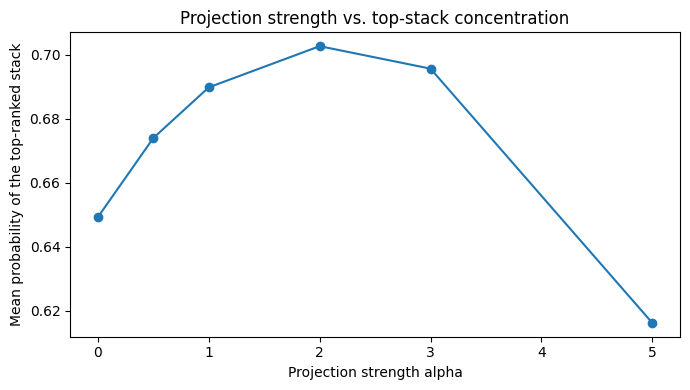

,condition,alpha,template,top_stack,top_stack_probability,top_stack_score
5,alpha_0_baseline,0.0000,"For the prototype, engineers selected <mask>, ...",local server + java + angular,0.5661,-40.4243
6,alpha_0_baseline,0.0000,"The application setup included <mask>, <mask>,...",local server + java + angular,0.7570,-37.9938
7,alpha_0_baseline,0.0000,"The architecture note listed <mask>, <mask>, a...",local server + java + html,0.3556,-42.7657
8,alpha_0_baseline,0.0000,"The project used <mask> for deployment, <mask>...",local server + java + html,0.7657,-45.3423
9,alpha_0_baseline,0.0000,"The software system combined <mask>, <mask>, a...",local server + java + angular,0.8019,-37.3207
0,alpha_0.5,0.5000,"For the prototype, engineers selected <mask>, ...",local server + java + angular,0.5847,-40.4809
1,alpha_0.5,0.5000,"The application setup included <mask>, <mask>,...",local server + java + angular,0.7612,-38.1994
2,alpha_0.5,0.5000,"The architecture note listed <mask>, <mask>, a...",local server + java + html,0.4076,-42.9693
3,alpha_0.5,0.5000,"The project used <mask> for deployment, <mask>...",local server + java + html,0.8058,-46.0674
4,alpha_0.5,0.5000,"The software system combined <mask>, <mask>, a...",local server + java + angular,0.8104,-37.5620


In [ ]:
plt.figure(figsize=(7, 4))
plt.plot(sweep_overall["alpha"], sweep_overall["mean_top_stack_probability"], marker="o")
plt.title("Projection strength vs. top-stack concentration")
plt.xlabel("Projection strength alpha")
plt.ylabel("Mean probability of the top-ranked stack")
plt.tight_layout()
plt.show()

sweep_summary.sort_values(["alpha", "template"]).head(40)

## Interpreting Projection Strength vs. Top-Stack Concentration

This graph shows how strongly the model concentrates around its top-ranked technology stack as projection strength increases.

The baseline condition (`alpha = 0`) represents the original pretrained model with no projection applied. Higher alpha values apply increasingly aggressive projection to remove part of the learned technical preference direction identified earlier in the notebook.

The y-axis measures the **mean probability assigned to the top-ranked stack** across prompts. Higher values indicate that the model is concentrating more strongly around one dominant stack, while lower values indicate a more distributed probability distribution across multiple stack combinations.

Interestingly, the results do not show a simple “more projection = less bias” pattern.

Instead, moderate projection strengths (`alpha = 0.5` to `alpha = 3`) increased concentration around the dominant stack. This suggests that the projection did not cleanly remove the learned preference structure. In this setting, projection may have unintentionally sharpened or reinforced existing stack-level associations.

At very high projection strength (`alpha = 5`), concentration dropped substantially. However, this decrease should not automatically be interpreted as successful debiasing. A lower top-stack probability may reflect representation instability, probability redistribution, or projection-induced distortion rather than genuine neutrality.

Overall, the graph suggests that the model’s stack-level preferences are relatively robust and not easily removed through a single geometric projection direction. The dominant stack patterns remained stable across projection settings, indicating that the learned associations may be distributed across many interacting parts of the model rather than concentrated in one removable direction.

This experiment also highlights an important lesson about mitigation techniques: stronger debiasing is not always better. Aggressive projection can destabilize ranking behavior and reduce representation quality instead of cleanly eliminating preference patterns.

A reliable debiasing evaluation would require larger-scale testing across:

* more diverse prompts,
* additional software-engineering domains,
* downstream coding tasks,
* multiple model families,
* and robustness analyses under different evaluation settings.

This tutorial experiment should therefore be interpreted as an exploratory demonstration of how technical preference structures can be measured, visualized, and experimentally modified.
